## Charles Book Club: Targeting Buyers for The Art History of Florence
A Database Marketing Case Study Using RFM Segmentation, k-Nearest Neighbours, and Logistic Regression

### Introduction
The Charles Book Club (CBC) is a specialty book distributor that sells through direct marketing. Despite growth in its mailing volume, catalogue and customer base, profits were declining, likely due to untargeted mailings to members with little or no likelihood of purchasing.

To address this issue, CBC conducted a test mailing for a new title, *The Art History of Florence*, to a random sample of 4,000 members and recorded their purchases. This report uses the test results to address one key business question: which members should receive the Florence mailing?

Following the assignment briefing, the report compares three approaches:<br>
1. RFM segmentation, an industry-standard approach based on Recency, Frequency and Monetary value.<br>
2. k-Nearest Neighbours (k-NN), which combines RFM measures with purchase histories of titles similar to *The Art History of Florence*.<br>
3. Logistic regression, which estimates each member’s probability of purchasing the title.


### Setup and Data Preparation

In [1]:
# Load packages
library(dplyr)    
library(tidyr)    
library(ggplot2) 
library(scales)  
library(caret)    
library(FNN)     
library(knitr)    


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Loading required package: lattice



In [2]:
# Consistent colour palette for all charts
col_buy <- "#2E5597" 
col_no <- "#A9B4C2" 
col_base <- "#C0392B"
theme_set(theme_minimal(base_size = 10) +
          theme(plot.title = element_text(face = "bold"),
                legend.position = "top"))

### Import and inspect the data

In [3]:
cbc <- read.csv("CharlesBookClub.csv",check.names = FALSE)

In [5]:
# Check for missing values
sum(is.na(cbc))              

[1] 0

In [6]:
# Change one column with a syntactic name
names(cbc)[names(cbc) == "Related Purchase"] <- "RelatedPurch"

In [7]:
str(cbc[,1:19])

'data.frame':	4000 obs. of  19 variables:
 $ Seq#        : int  1 2 3 4 5 6 7 8 9 10 ...
 $ ID#         : int  25 29 46 47 51 60 61 79 81 90 ...
 $ Gender      : int  1 0 1 1 1 1 1 1 1 1 ...
 $ M           : int  297 128 138 228 257 145 190 187 252 240 ...
 $ R           : int  14 8 22 2 10 6 16 14 10 6 ...
 $ F           : int  2 2 7 1 1 2 1 1 1 3 ...
 $ FirstPurch  : int  22 10 56 2 10 12 16 14 10 20 ...
 $ ChildBks    : int  0 0 2 0 0 0 0 1 0 0 ...
 $ YouthBks    : int  1 0 1 0 0 0 0 0 0 0 ...
 $ CookBks     : int  1 0 2 0 0 0 0 0 0 1 ...
 $ DoItYBks    : int  0 0 0 0 0 0 0 0 0 0 ...
 $ RefBks      : int  0 0 1 0 0 0 0 0 0 0 ...
 $ ArtBks      : int  0 0 0 0 0 0 0 0 0 0 ...
 $ GeogBks     : int  0 0 1 0 0 0 1 0 0 0 ...
 $ ItalCook    : int  0 0 1 0 0 0 0 0 0 0 ...
 $ ItalAtlas   : int  0 0 0 0 0 0 0 0 0 0 ...
 $ ItalArt     : int  0 0 0 0 0 0 0 0 0 0 ...
 $ Florence    : int  0 0 0 0 0 0 0 0 0 0 ...
 $ RelatedPurch: int  0 0 2 0 0 0 1 0 0 0 ...


The dataset contains 4,000 customers and 24 columns, with no missing values. The variables include customer identifiers (Seq# and ID#), gender, RFM measures, months since first purchase, and purchase counts by book category and title. The outcome variable, Florence, indicates whether a customer purchased the Florence book (1 = purchased). The last five columns (Mcode, Rcode, Fcode, Yes_Florence and No_Florence) are derived variables and are therefore checked for consistency before use.

### Validate the derived columns

In [8]:
chk_R <- all(cbc$Rcode == as.integer(cut(cbc$R,c(-Inf,2,6,12,Inf))))
chk_F <- all(cbc$Fcode == pmin(cbc$F,3))
chk_M <- all(cbc$Mcode == as.integer(cut(cbc$M,c(-Inf,25,50,100,200,Inf))))

In [9]:
chk_rel <- all(cbc$RelatedPurch ==
               with(cbc,ArtBks+GeogBks+ItalCook+ItalAtlas+ItalArt))

In [10]:
c(Rcode = chk_R,Fcode = chk_F,Mcode = chk_M,RelatedPurch = chk_rel)

Rcode        Fcode        Mcode RelatedPurch 
        TRUE         TRUE         TRUE         TRUE

All four checks return TRUE, confirming that the supplied Rcode, Fcode and Mcode follow the specified cut-offs (Recency: 0–2, 3–6, 7–12, and 13+ months; Frequency: 1, 2 and 3+ books; Monetary: $\$$0–25, $\$$26–50, $\$$51–100, $\$$101–200 and $\$$201+). RelatedPurch also correctly represents the sum of the five Florence-related purchase counts.

### Partition into training (60%) and validation (40%)

In [8]:
set.seed(1)
train.index <- sample(1:nrow(cbc),0.6*nrow(cbc))
train <- cbc[ train.index,]
valid <- cbc[-train.index,]

data.frame(Set = c("Training","Validation"),
           Customers = c(nrow(train),nrow(valid)),
           Buyers = c(sum(train$Florence),sum(valid$Florence)),
           ResponseRate = percent(c(mean(train$Florence),mean(valid$Florence)),0.01)) |>
kable()



|Set        | Customers| Buyers|ResponseRate |
|:----------|---------:|------:|:------------|
|Training   |      2400|    209|8.71%        |
|Validation |      1600|    129|8.06%        |

The 4,000 records are randomly divided into 2,400 training and 1,600 validation datasets. The analysis follows the 60/40 split. All models are fitted using the training set and evaluated on the unseen validation set. The response rates are similar (8.71% and 8.06%), indicating a balanced split.

### Descriptive Statistics and Customer Insights

In [9]:
num_vars <- c("M","R","F","FirstPurch","RelatedPurch")
desc <- sapply(cbc[,num_vars],function(x)
  c(Mean = mean(x),SD = sd(x),Min = min(x),Median = median(x),Max = max(x)))
kable(round(t(desc),2))



|             |   Mean|     SD| Min| Median| Max|
|:------------|------:|------:|---:|------:|---:|
|M            | 208.09| 100.95|  15|    208| 479|
|R            |  13.39|   8.10|   2|     12|  36|
|F            |   3.83|   3.46|   1|      2|  12|
|FirstPurch   |  26.51|  18.35|   2|     20|  99|
|RelatedPurch |   0.88|   1.23|   0|      0|   8|

In [10]:
overall_rate <- mean(cbc$Florence)
percent(overall_rate,0.01)

[1] "8.45%"

A typical member has spent approximately $\$$208 (median), made their last purchase 12 months ago (median), completed two purchases (median), and joined about two years ago. The mean purchase count of 3.8 is higher due to a small group of heavy buyers. Most members have not purchased any related books in the art, geography or Italian categories. 

Only 8.45% of the test sample purchased the Florence title. This low response rate highlights the central business problem: mailing every member would result in more than 90% of mailings reaching non-buyers.
 
### Response by gender

In [11]:
g <- cbc |>
  mutate(Gender = factor(Gender,0:1,c("Male","Female"))) |>
  group_by(Gender) |>
  summarise(Customers = n(),Buyers = sum(Florence),Rate = mean(Florence))
kable(g |> mutate(Rate = percent(Rate,0.1)))



|Gender | Customers| Buyers|Rate  |
|:------|---------:|------:|:-----|
|Male   |      1182|    130|11.0% |
|Female |      2818|    208|7.4%  |

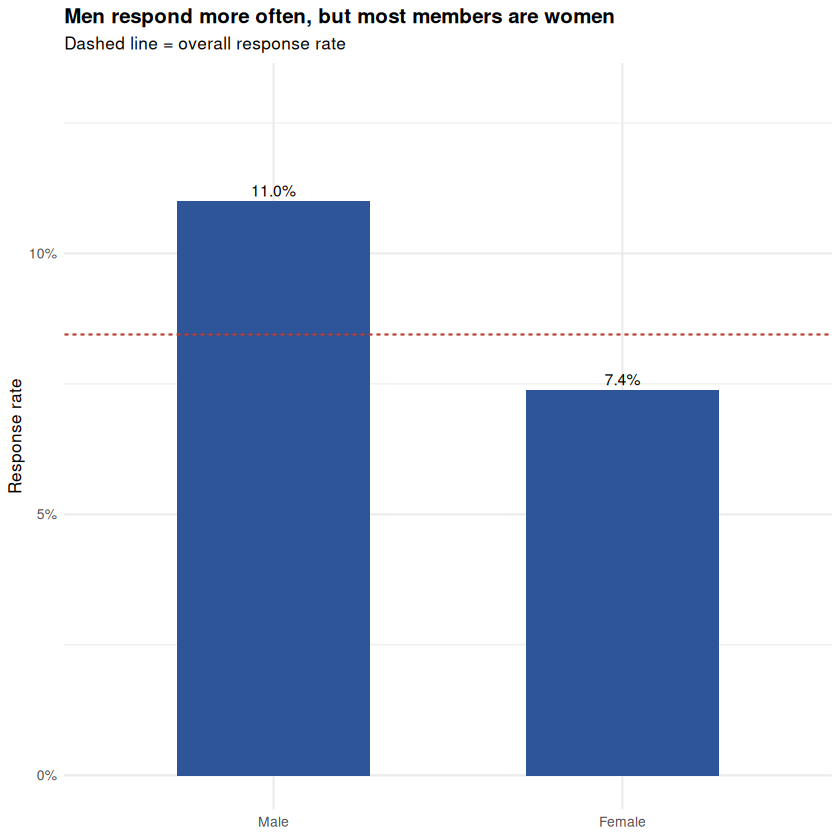

In [12]:
ggplot(g,aes(Gender,Rate)) +
geom_col(fill = col_buy,width = 0.55) +
geom_hline(yintercept = overall_rate,linetype = "dashed",colour = col_base) +
geom_text(aes(label = percent(Rate,0.1)),vjust = -0.4,size = 3.2) +
scale_y_continuous(labels = percent,limits = c(0, 0.13)) +
labs(x = NULL,y = "Response rate",title = "Men respond more often, but most members are women",
     subtitle = "Dashed line = overall response rate")

Approximately 70% of members are women, but men have a higher response rate (11.0% versus 7.4%). Although gender alone is a weak targeting variable, it may provide additional predictive information when combined with purchase history. This is examined further in the logistic regression model.

### Response by R, F and M categories

In [13]:
rfm_long <- bind_rows(
  cbc |> group_by(Code = Rcode) |> summarise(Rate = mean(Florence),n = n()) |>
    mutate(Dimension = "Recency (1 = most recent)"),
  cbc |> group_by(Code = Fcode) |> summarise(Rate = mean(Florence),n = n()) |>
    mutate(Dimension = "Frequency (3 = 3+ books)"),
  cbc |> group_by(Code = Mcode) |> summarise(Rate = mean(Florence),n = n()) |>
    mutate(Dimension = "Monetary (5 = $201+)"))

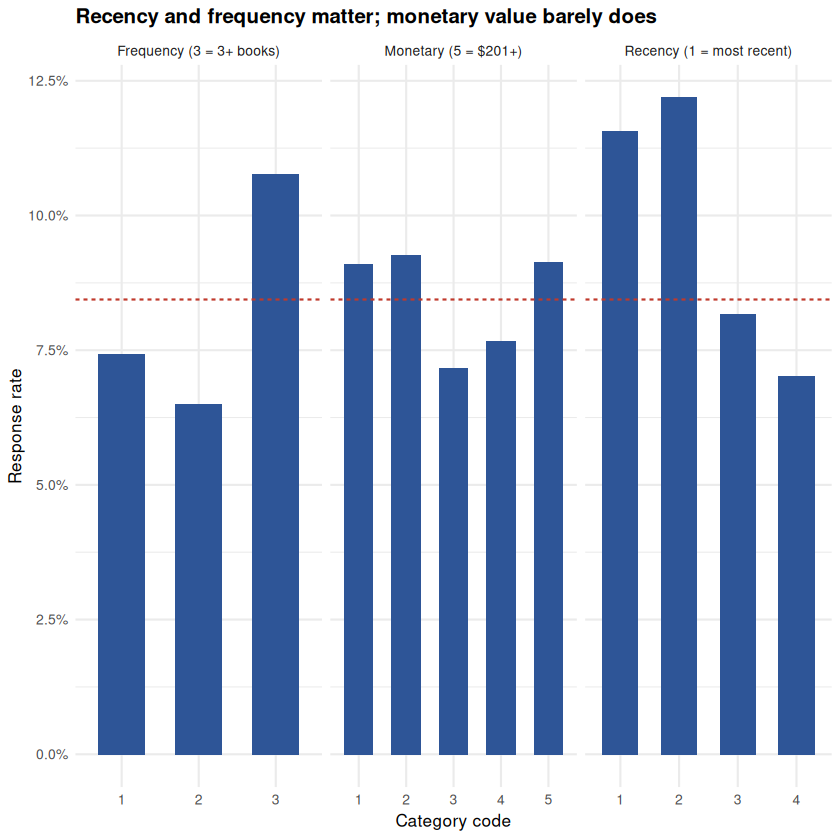

In [14]:
ggplot(rfm_long,aes(factor(Code),Rate)) +
geom_col(fill = col_buy,width = 0.6) +
geom_hline(yintercept = overall_rate,linetype = "dashed",colour = col_base) +
facet_wrap(~ Dimension,scales = "free_x") +
scale_y_continuous(labels = percent) +
labs(x = "Category code",y = "Response rate",
     title = "Recency and frequency matter; monetary value barely does")

Recency follows the expected RFM pattern: members who purchased within the last six months have a response rate of approximately 12%, compared with 7% among those inactive for over a year. Frequency has a positive effect only at the highest level, with members making three or more purchases achieving a response rate of about 11%. Monetary value, however, shows no clear relationship with response. Higher spending does not translate into a greater likelihood of purchasing this particular title. Thus, the standard RFM assumption that higher spending leads to higher response rates holds only partially in this case.

### Previous purchase behaviour

In [15]:
cats <- c("ChildBks","YouthBks","CookBks","DoItYBks","RefBks",
          "ArtBks","GeogBks","ItalCook","ItalAtlas","ItalArt")

cat_means <- cbc |>
mutate(Group = ifelse(Florence == 1,"Buyer","Non-buyer")) |>
group_by(Group) |>
summarise(across(all_of(cats),mean)) |>
pivot_longer(-Group,names_to = "Category",values_to = "Mean")

# Ratio of buyer mean to non-buyer mean, used to order the chart
ratio <- cat_means |> 
pivot_wider(names_from = Group,values_from = Mean) |>
mutate(Ratio = Buyer / `Non-buyer`) |> 
arrange(Ratio)

kable(ratio |> mutate(across(where(is.numeric),~ round(.x, 3))))



|Category  | Buyer| Non-buyer| Ratio|
|:---------|-----:|---------:|-----:|
|CookBks   | 0.713|     0.733| 0.973|
|ChildBks  | 0.692|     0.635| 1.090|
|ItalCook  | 0.139|     0.124| 1.122|
|DoItYBks  | 0.396|     0.347| 1.144|
|YouthBks  | 0.370|     0.299| 1.238|
|RefBks    | 0.314|     0.251| 1.250|
|ItalAtlas | 0.053|     0.036| 1.477|
|GeogBks   | 0.574|     0.370| 1.550|
|ArtBks    | 0.518|     0.268| 1.933|
|ItalArt   | 0.086|     0.042| 2.040|

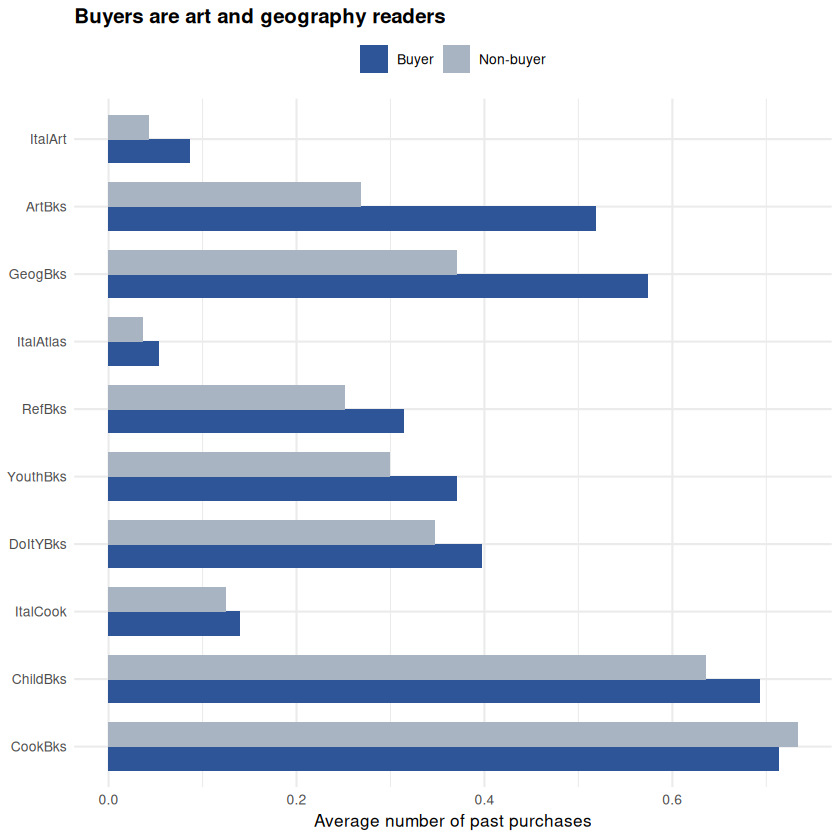

In [16]:
ggplot(cat_means,aes(factor(Category,levels = ratio$Category),Mean,fill = Group)) +
geom_col(position = "dodge",width = 0.7) +
coord_flip() +
scale_fill_manual(values = c(Buyer = col_buy,`Non-buyer` = col_no)) +
labs(x = NULL,y = "Average number of past purchases",fill = NULL,
     title = "Buyers are art and geography readers")

Florence buyers have purchased nearly twice as many art books and Italian Art titles as non-buyers, along with approximately 55% more geography books. In contrast, purchases of cookbooks, *Secrets of Italian Cooking* and children’s books are similar across both groups. This suggest buyers are primarily attracted by the subject matter (art and culture) rather than a general interest in Italy.

### Response rates by number of art books and related purchases

In [17]:
art_rel <- bind_rows(
  cbc |> mutate(Level = pmin(ArtBks,3)) |> group_by(Level) |>
    summarise(Rate = mean(Florence),n = n()) |> mutate(Variable = "Art books bought"),
  cbc |> mutate(Level = pmin(RelatedPurch,3)) |> group_by(Level) |>
    summarise(Rate = mean(Florence),n = n()) |> mutate(Variable = "Related books bought"))
art_rel$Level <- factor(art_rel$Level,0:3,c("0","1","2","3+"))
kable(art_rel |> mutate(Rate = percent(Rate,0.1)))



|Level |Rate  |    n|Variable             |
|:-----|:-----|----:|:--------------------|
|0     |7.2%  | 3108|Art books bought     |
|1     |10.3% |  669|Art books bought     |
|2     |18.7% |  187|Art books bought     |
|3+    |30.6% |   36|Art books bought     |
|0     |7.0%  | 2095|Related books bought |
|1     |6.8%  |  983|Related books bought |
|2     |10.2% |  500|Related books bought |
|3+    |17.5% |  422|Related books bought |

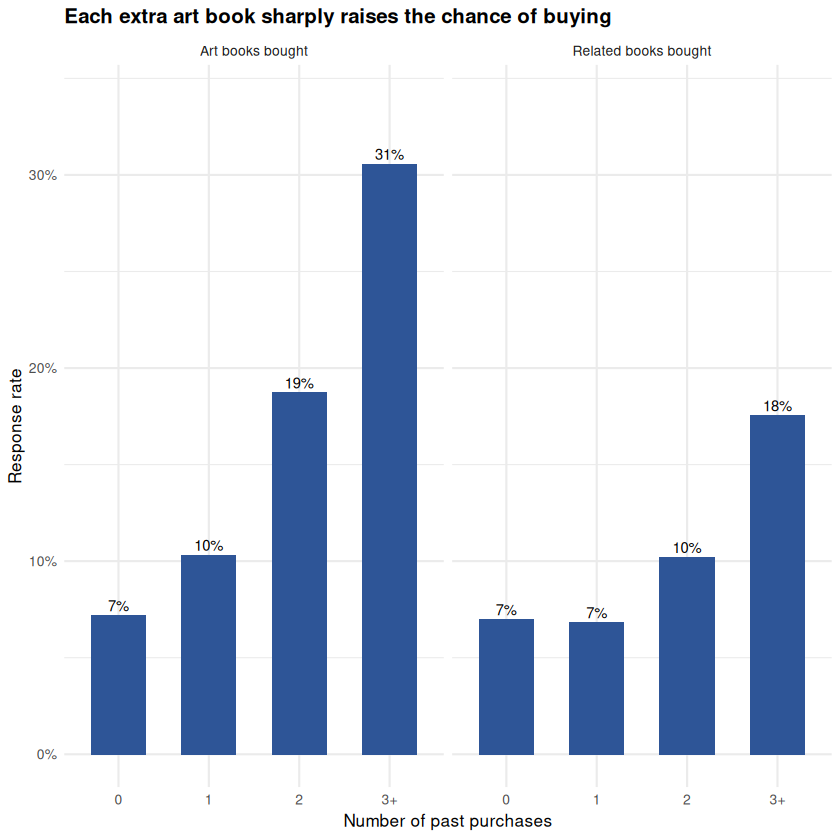

In [18]:
ggplot(art_rel, aes(Level,Rate)) +
geom_col(fill = col_buy,width = 0.6) +
geom_text(aes(label = percent(Rate, 1)),vjust = -0.4,size = 3) +
facet_wrap(~ Variable) +
scale_y_continuous(labels = percent,limits = c(0, 0.34)) +
labs(x = "Number of past purchases",y = "Response rate",
     title = "Each extra art book sharply raises the chance of buying")

The response rate increases from approximately 7% among members with no art books purchases to about 31% among those with three or more, exceeding three times the overall average. Related purchases show a similar upward trend. This indicates that product affinity is a stronger predictor of response than general RFM behaviour. Accordingly, both the k-NN and logistic regression models incorporate these purchase patterns explicitly.

### RFM Segmentation

In [19]:
train_rate <- mean(train$Florence)
percent(train_rate,0.01)                         

[1] "8.71%"

In [20]:
rfm_tab <- train |>
  group_by(Rcode,Fcode,Mcode) |>
  summarise(Customers = n(),Buyers = sum(Florence),
            Rate = mean(Florence),.groups = "drop")

In [21]:
all_combos <- expand.grid(Rcode = 1:4,Fcode = 1:3,Mcode = 1:5)
rfm_full <- all_combos |> left_join(rfm_tab,by = c("Rcode","Fcode","Mcode")) |>
  mutate(Customers = coalesce(Customers,0L),Buyers = coalesce(Buyers,0L))

c(possible = nrow(rfm_full),populated = sum(rfm_full$Customers > 0),
  above_average = sum(rfm_tab$Rate > train_rate))

possible     populated above_average 
           60            51            19

In [22]:
rfm_full |>
  mutate(Cell = ifelse(Customers == 0,"-",
                       paste0(percent(Rate, 1)," (", Customers, ")")),
         FM = paste0("F",Fcode,"-M", Mcode)) |>
  select(Rcode,FM,Cell) |>
  pivot_wider(names_from = Rcode,values_from = Cell,names_prefix = "R") |>
  kable(caption = "Training response rate (customers) for every RFM combination; - = empty cell")



Table: Training response rate (customers) for every RFM combination; - = empty cell

|FM    |R1       |R2       |R3        |R4       |
|:-----|:--------|:--------|:---------|:--------|
|F1-M1 |0% (2)   |33% (3)  |0% (6)    |0% (9)   |
|F2-M1 |-        |-        |-         |-        |
|F3-M1 |-        |-        |-         |-        |
|F1-M2 |0% (4)   |33% (9)  |0% (26)   |5% (20)  |
|F2-M2 |50% (2)  |0% (4)   |7% (15)   |0% (11)  |
|F3-M2 |100% (1) |-        |0% (1)    |0% (2)   |
|F1-M3 |0% (3)   |14% (22) |6% (31)   |8% (61)  |
|F2-M3 |0% (9)   |17% (24) |10% (40)  |2% (56)  |
|F3-M3 |0% (2)   |33% (6)  |0% (16)   |12% (17) |
|F1-M4 |25% (16) |4% (27)  |7% (83)   |7% (101) |
|F2-M4 |0% (16)  |11% (35) |8% (73)   |6% (121) |
|F3-M4 |6% (16)  |15% (41) |7% (74)   |7% (105) |
|F1-M5 |12% (26) |18% (28) |4% (120)  |8% (132) |
|F2-M5 |12% (17) |11% (44) |4% (101)  |7% (153) |
|F3-M5 |17% (53) |15% (93) |15% (215) |7% (308) |

In [23]:
above <- rfm_tab |> filter(Rate > train_rate) |> arrange(desc(Rate))
kable(above |> mutate(Rate = percent(Rate,0.1)),
      caption = "RFM combinations with above-average response in the training data")



Table: RFM combinations with above-average response in the training data

| Rcode| Fcode| Mcode| Customers| Buyers|Rate   |
|-----:|-----:|-----:|---------:|------:|:------|
|     1|     3|     2|         1|      1|100.0% |
|     1|     2|     2|         2|      1|50.0%  |
|     2|     1|     1|         3|      1|33.3%  |
|     2|     1|     2|         9|      3|33.3%  |
|     2|     3|     3|         6|      2|33.3%  |
|     1|     1|     4|        16|      4|25.0%  |
|     2|     1|     5|        28|      5|17.9%  |
|     1|     3|     5|        53|      9|17.0%  |
|     2|     2|     3|        24|      4|16.7%  |
|     3|     3|     5|       215|     33|15.3%  |
|     2|     3|     5|        93|     14|15.1%  |
|     2|     3|     4|        41|      6|14.6%  |
|     2|     1|     3|        22|      3|13.6%  |
|     1|     2|     5|        17|      2|11.8%  |
|     4|     3|     3|        17|      2|11.8%  |
|     1|     1|     5|        26|      3|11.5%  |
|     2|     2|     4|  

The overall training response rate is 8.71%. Of the 60 theoretical combinations, 51 contain customers and 19 exceed the overall rate. These 19 cells (listed above) cover 692 training customers, or 29% of the training set. However, many cells have very small sample sizes: the 100% response rate comes from a single customer, while several 33% rates are based on just three to nine customers. Such rates are likely driven by sampling noise, highlighting the need for validation.

### Mailing only the above-average combinations: Validation response

In [24]:
key <- function(d) paste(d$Rcode,d$Fcode,d$Mcode)
target <- valid[key(valid) %in% key(above),]

rfm_val <- c(Mailed = nrow(target),Buyers = sum(target$Florence),
             ResponseRate = mean(target$Florence),
             ValidationOverall = mean(valid$Florence),
             Lift = mean(target$Florence)/mean(valid$Florence))

round(rfm_val,4)

Mailed            Buyers      ResponseRate ValidationOverall 
         446.0000           46.0000            0.1031            0.0806 
             Lift 
           1.2792

In the validation data, the above-average cells cover 446 customers (28% of the list) and generate 46 buyers, yielding a response rate of 10.3%, compared with 8.1% for the overall validation set. This represents a modest lift of 1.28×. The targeted mailing captures 36% of all buyers while reaching only 28% of customers. Thus, RFM targeting provides some improvement, but its performance is considerably weaker than the 10–100% response rates observed in training.

### Three RFM segments and their lift curve

In [25]:
seg_map <- rfm_tab |>
  mutate(Segment = case_when(Rate > 2*train_rate ~ 1,     
                             Rate > train_rate ~ 2,     
                             TRUE ~ 3)) 

train_seg <- train |> left_join(seg_map[,c("Rcode","Fcode","Mcode","Segment")],
                                by = c("Rcode","Fcode","Mcode"))

valid_seg <- valid |> left_join(seg_map[,c("Rcode","Fcode","Mcode","Segment")],
                                by = c("Rcode","Fcode","Mcode")) |>
  mutate(Segment = coalesce(Segment,3))

In [26]:
seg_summary <- function(d) d |> group_by(Segment) |>
  summarise(Customers = n(),Buyers = sum(Florence),Rate = mean(Florence))

kable(seg_summary(train_seg) |> mutate(Rate = percent(Rate,0.1)),
      caption = "Segment response rates - training data")



Table: Segment response rates - training data

| Segment| Customers| Buyers|Rate  |
|-------:|---------:|------:|:-----|
|       1|        65|     17|26.2% |
|       2|       627|     89|14.2% |
|       3|      1708|    103|6.0%  |

In [27]:
seg_val <- seg_summary(valid_seg)
kable(seg_val |> mutate(Rate = percent(Rate,0.1)),
      caption = "Segment response rates - validation data")



Table: Segment response rates - validation data

| Segment| Customers| Buyers|Rate  |
|-------:|---------:|------:|:-----|
|       1|        42|      4|9.5%  |
|       2|       404|     42|10.4% |
|       3|      1154|     83|7.2%  |

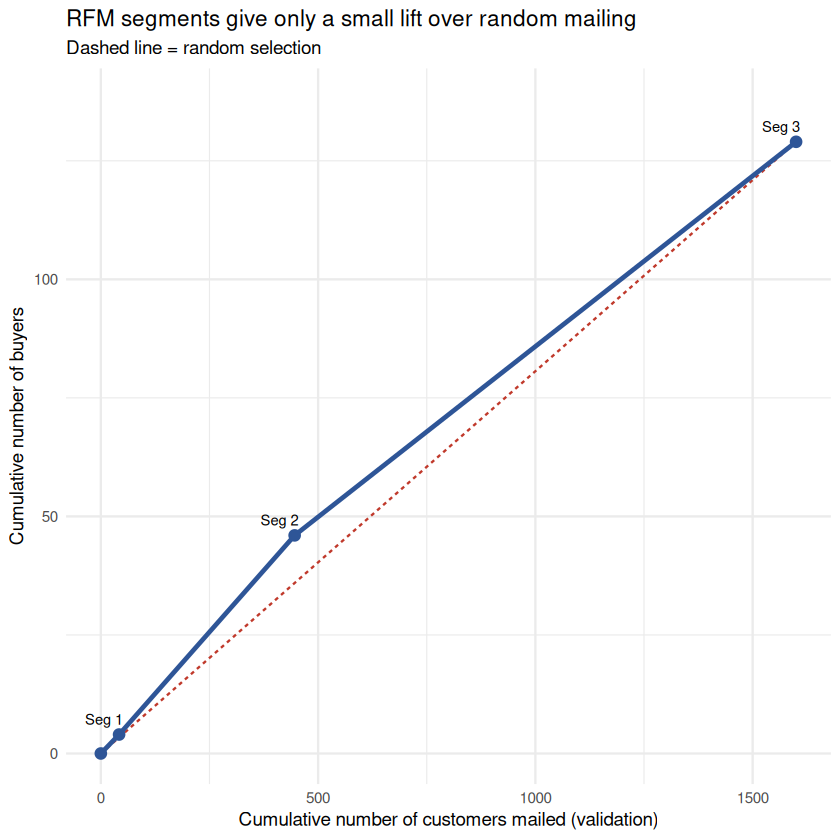

In [28]:
lift_rfm <- seg_val |> arrange(Segment) |>
  mutate(CumCustomers = cumsum(Customers), 
         CumBuyers = cumsum(Buyers)) |>
  add_row(Segment = 0,CumCustomers = 0,CumBuyers = 0,.before = 1)

ggplot(lift_rfm,aes(CumCustomers,CumBuyers)) +
annotate("segment",x = 0,y = 0,xend = nrow(valid),yend = sum(valid$Florence),
         linetype = "dashed",colour = col_base) +
geom_line(colour = col_buy,linewidth = 1) +
geom_point(colour = col_buy,size = 2.5) +
geom_text(data = filter(lift_rfm,Segment != 0),aes(label = paste("Seg",Segment)),
          vjust = -0.9,hjust = 0.9,size = 3) +
scale_y_continuous(expand = expansion(mult = c(0.05,0.12))) +
labs(x = "Cumulative number of customers mailed (validation)",
     y = "Cumulative number of buyers",
     title = "RFM segments give only a small lift over random mailing",
     subtitle = "Dashed line = random selection") +
theme_minimal()

The training data show clear separation between segments, with Segment 1 achieving a response rate well above average. However, this pattern does not hold in validation. Segment 1 (42 customers) achieves a response rate of only 9.5%, slightly below Segment 2 (10.4%), while Segment 3 records 7.2%. The lift curve rises only marginally above the random-selection baseline, with most of the benefit coming from Segment 2. The exceptionally high response rates observed in training were largely driven by small groups that performed well by chance. This highlights a key limitation of RFM: it overlooks customerss reading preferences, which Section 3 identified as the strongest driver of response.

### k-Nearest Neighbours
To address this limitation, the k-NN model uses five predictors: R, F, M, FirstPurch and RelatedPurch. This combines purchasing behaviour with customers' affinity for the Florence title.

In [29]:
knn_vars <- c("R","F","M","FirstPurch","RelatedPurch")

norm <- preProcess(train[,knn_vars],method = c("center","scale"))
train.norm <- predict(norm,train[,knn_vars])
valid.norm <- predict(norm,valid[,knn_vars])
round(sapply(train.norm,function(x) c(mean = mean(x),sd = sd(x))),3)

,R,F,M,FirstPurch,RelatedPurch
mean,0,0,0,0,0
sd,1,1,1,1,1


Because k-NN relies on distance calculations, variables with larger numerical ranges can dominate those with smaller ranges. For example, M ranges up to $479, while RelatedPurch ranges from 0 to 8. Standardising all five predictors to a mean of 0 and a standard deviation of 1 ensures that each contributes comparably to the distance calculations. The scaling parameters are estimated using training data only, preventing information leakage from the validation set.

### k-NN classification for k = 1 to 11

In [30]:
auc <- function(score,y) {
  r <- rank(score)
  n1 <- sum(y) 
  n0 <- length(y)-n1
  (sum(r[y == 1])-n1*(n1+1)/2)/(n1*n0)
}

knn_results <- lapply(1:11,function(k) {
  set.seed(1)                                  
  pred <- FNN::knn(train.norm,valid.norm, 
                   cl = factor(train$Florence), 
                   k = k, prob = TRUE)
  p_win <- attr(pred,"prob")
  score <- ifelse(pred == "1",p_win,1-p_win)
  cm <- confusionMatrix(pred,factor(valid$Florence),positive = "1")
  data.frame(k = k,
             Accuracy = cm$overall["Accuracy"],
             Sensitivity = cm$byClass["Sensitivity"],
             PredBuyers = sum(pred == "1"),
             AUC = auc(score,valid$Florence))
}) |> bind_rows()
rownames(knn_results) <- NULL
kable(knn_results,digits = 3)



|  k| Accuracy| Sensitivity| PredBuyers|   AUC|
|--:|--------:|-----------:|----------:|-----:|
|  1|    0.859|       0.101|        123| 0.513|
|  2|    0.914|       0.016|         13| 0.529|
|  3|    0.902|       0.031|         35| 0.556|
|  4|    0.919|       0.016|          5| 0.552|
|  5|    0.909|       0.016|         20| 0.544|
|  6|    0.919|       0.008|          3| 0.551|
|  7|    0.916|       0.008|          7| 0.553|
|  8|    0.919|       0.008|          2| 0.558|
|  9|    0.917|       0.008|          5| 0.558|
| 10|    0.919|       0.008|          3| 0.551|
| 11|    0.919|       0.016|          4| 0.551|

In [31]:
naive_acc <- 1-mean(valid$Florence)         
best_k <- knn_results$k[which.max(knn_results$Accuracy)]
c(naive_accuracy = round(naive_acc, 4),best_k = best_k)

naive_accuracy         best_k 
        0.9194         8.0000

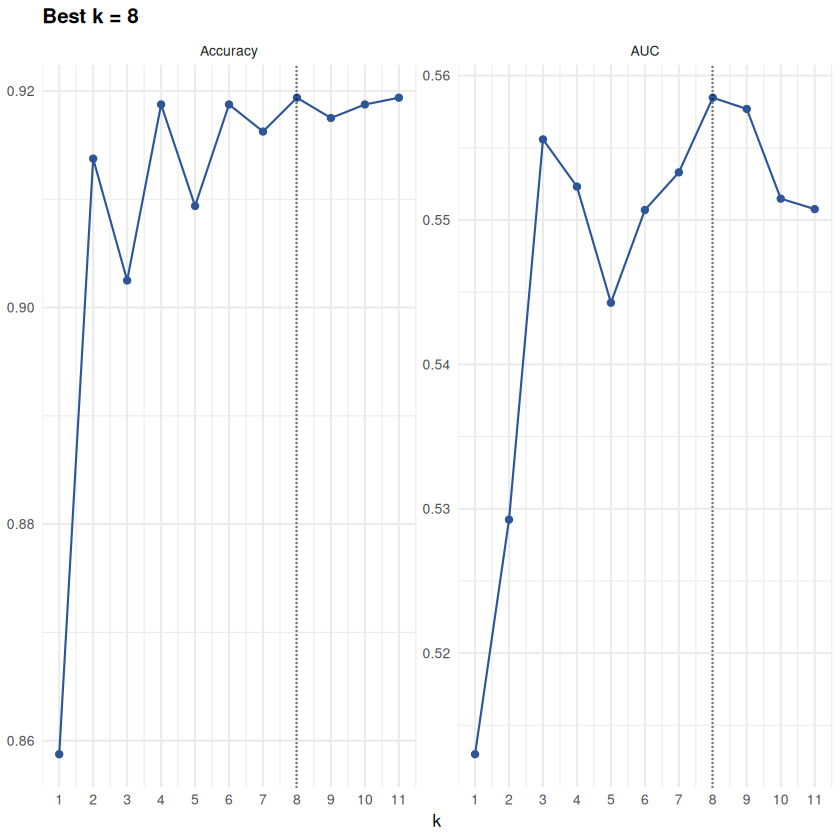

In [32]:
knn_results |>
  select(k,Accuracy,AUC) |>
  pivot_longer(-k) |>
  ggplot(aes(k,value)) +
  geom_line(colour = col_buy) + geom_point(colour = col_buy) +
  geom_vline(xintercept = best_k,linetype = "dotted") +
  facet_wrap(~ name,scales = "free_y") +
  scale_x_continuous(breaks = 1:11) +
  labs(y = NULL,title = paste("Best k =",best_k))

Validation accuracy peaks at k = 8 (91.94%), which also ties for the highest AUC, indicating strong customer-ranking performance. Thus, k = 8 is selected as the best model. However, accuracy is misleading because predicting that no customers will buy already achieves 91.94%. At k = 8, the model predicts only two buyers. Since buyers are rare, a 50% majority vote threshold seldom produces a positive prediction. Therefore, k-NN is more useful for ranking customers based on the proportion of neighbours who purchased, which forms the basis of the lift curve. 

### Lift curve for the best-k classifier

In [33]:
gains_curve <- function(score,actual,model) {
  o <- order(score,decreasing = TRUE)
  data.frame(Model = model,
             Customers = c(0,seq_along(o)),
             Buyers = c(0,cumsum(actual[o])))
}

In [34]:
lift_at <- function(score,actual,n = c(160,320,480,800)) {
  o <- order(score,decreasing = TRUE)
  data.frame(TopN = n,Pct = percent(n/length(actual)),
             ModelBuyers = sapply(n,function(i) sum(actual[o][1:i])),
             RandomBuyers = round(n*mean(actual),1)) |>
    mutate(Lift = round(ModelBuyers/RandomBuyers,2))
}
set.seed(1)
knn_best <- FNN::knn(train.norm,valid.norm, cl = factor(train$Florence),
                     k = best_k,prob = TRUE)
knn_score <- ifelse(knn_best == "1",attr(knn_best,"prob"),1-attr(knn_best,"prob"))

kable(lift_at(knn_score,valid$Florence),
      caption = paste0("Expected buyers in the top-N customers: k-NN (k = ", best_k, ") vs random"))



Table: Expected buyers in the top-N customers: k-NN (k = 8) vs random

| TopN|Pct | ModelBuyers| RandomBuyers| Lift|
|----:|:---|-----------:|------------:|----:|
|  160|10% |          22|         12.9| 1.71|
|  320|20% |          33|         25.8| 1.28|
|  480|30% |          51|         38.7| 1.32|
|  800|50% |          75|         64.5| 1.16|

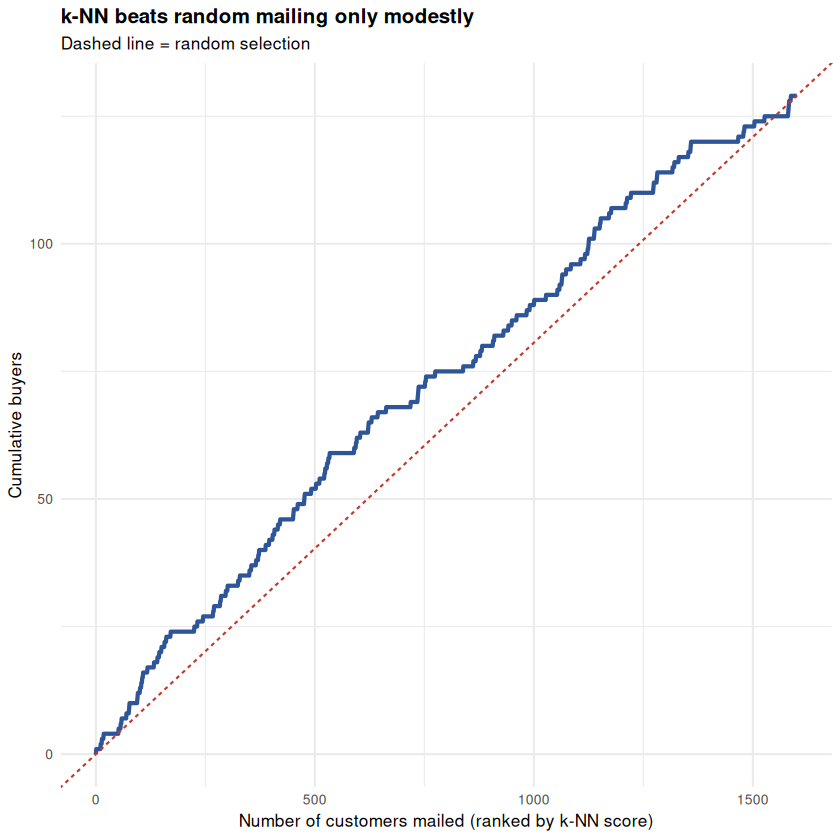

In [35]:
g_knn <- gains_curve(knn_score,valid$Florence, paste0("k-NN classification (k = ",best_k,")"))

ggplot(g_knn, aes(Customers,Buyers)) +
geom_line(colour = col_buy,linewidth = 0.9) +
geom_abline(slope = mean(valid$Florence),intercept = 0,linetype = "dashed",colour = col_base) +
labs(x = "Number of customers mailed (ranked by k-NN score)",y = "Cumulative buyers",
     title = "k-NN beats random mailing only modestly",subtitle = "Dashed line = random selection")

The lift curve lies slightly above the random-selection baseline. Mailing the top 20% of customers (320) captures the number of buyers reported in the table, achieving a lift of approximately 1.28× over random selection. With k = 8, the model produces only nine possible scores (0/8 to 8/8), resulting in many tied customers. This explains the stepped curve and its near-linear sections. The modest lift also suggests that the five predictors, which are primarily RFM-based, omit important factors driving customer response.

### k-NN prediction using distance-weighted averages

In [36]:
nn <- get.knnx(data = train.norm,query = valid.norm,k = best_k)

w <- 1 / (nn$nn.dist+1e-6)
neighbour_y <- matrix(train$Florence[nn$nn.index],ncol = best_k)
knn_pred <- rowSums(w*neighbour_y)/rowSums(w)

In [37]:
summary(knn_pred)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
0.00000 0.00000 0.00000 0.08224 0.12289 0.99998 

In [38]:
c(distinct_values = length(unique(round(knn_pred,6))),
  share_zero = mean(knn_pred == 0))

distinct_values      share_zero 
     735.000000        0.524375

In [39]:
kable(lift_at(knn_pred,valid$Florence),
      caption = "Expected buyers in the top-N customers: weighted k-NN prediction vs random")



Table: Expected buyers in the top-N customers: weighted k-NN prediction vs random

| TopN|Pct | ModelBuyers| RandomBuyers| Lift|
|----:|:---|-----------:|------------:|----:|
|  160|10% |          16|         12.9| 1.24|
|  320|20% |          34|         25.8| 1.32|
|  480|30% |          55|         38.7| 1.42|
|  800|50% |          75|         64.5| 1.16|

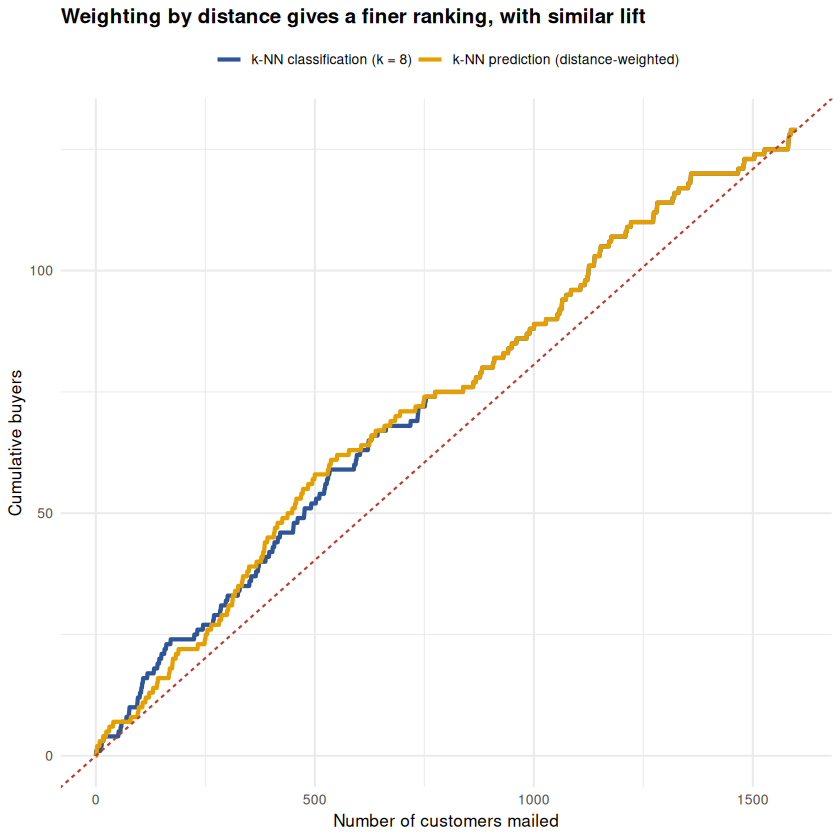

In [40]:
g_knnp <- gains_curve(knn_pred,valid$Florence,"k-NN prediction (distance-weighted)")
ggplot(bind_rows(g_knn,g_knnp),aes(Customers,Buyers,colour = Model)) +
geom_line(linewidth = 0.9) +
geom_abline(slope = mean(valid$Florence),intercept = 0,linetype = "dashed",colour = col_base) +
scale_colour_manual(values = c(col_buy,"#E69F00")) +
labs(x = "Number of customers mailed",y = "Cumulative buyers",colour = NULL,
     title = "Weighting by distance gives a finer ranking, with similar lift")

The k-NN prediction is a distance-weighted average of binary (0/1) outcomes. Each prediction therefore lies between 0 and 1 and can be interpreted as purchase propensity. The scores span the full range, although 52% of customers receive a score of exactly zero because none of their neighbours made a purchase. 

The two approaches differ in how they rank customers:<br>
• Classification assigns a binary 0/1 label, which is almost always 0 in this case. Its vote share has only nine possible values.<br>
• Prediction produces a continuous score with 735 distinct values. Closer neighbours receive greater weight, reducing ties and producing a smoother ranking.

Despite this difference, the two lift curves are similar. Distance weighting changes customer rankings but does not overcome the model's limited predictive power. Thus, k-NN based on these five predictors remains a relatively weak targeting tool.

### Logistic Regression

In [41]:
preds15 <- c("Gender","M","R","F","FirstPurch",cats)
length(preds15)

[1] 15

In [42]:
logit.full <- glm(Florence ~ .,data = train[,c(preds15,"Florence")], family = "binomial")
summary(logit.full)$coefficients |> round(4) |> 
kable()



|            | Estimate| Std. Error| z value| Pr(>&#124;z&#124;)|
|:-----------|--------:|----------:|-------:|------------------:|
|(Intercept) |  -2.3144|     0.2585| -8.9542|             0.0000|
|Gender      |  -0.3389|     0.1564| -2.1675|             0.0302|
|M           |   0.0001|     0.0009|  0.1431|             0.8862|
|R           |  -0.0299|     0.0156| -1.9206|             0.0548|
|F           |   0.2048|     0.0649|  3.1544|             0.0016|
|FirstPurch  |  -0.0005|     0.0110| -0.0459|             0.9634|
|ChildBks    |  -0.1774|     0.1058| -1.6770|             0.0935|
|YouthBks    |  -0.2621|     0.1518| -1.7267|             0.0842|
|CookBks     |  -0.3733|     0.1099| -3.3981|             0.0007|
|DoItYBks    |  -0.1842|     0.1330| -1.3852|             0.1660|
|RefBks      |  -0.2273|     0.1542| -1.4733|             0.1407|
|ArtBks      |   0.4824|     0.1012|  4.7661|             0.0000|
|GeogBks     |   0.2409|     0.0977|  2.4666|             0.0136|
|ItalCoo

All 15 predictors are included: gender, the four RFM/tenure measures, and the ten category and title counts. RelatedPurch is excluded because it is an exact sum of five other predictors and would introduce redundancy. The strongest positive effects are ArtBks, GeogBks and F, while the strongest negative effects are CookBks, Gender (women have lower odds, all else being equal) and R (a longer interval since the last purchase reduces the odds). M, FirstPurch, ItalCook and ItalArt contribute little once the other variables are accounted for. Each additional art book increases the odds of purchasing by approximately 62% (odds ratio = exp(0.48) = 1.62).

### Model B: Best subset of predictors

In [43]:
logit.step <- step(logit.full,direction = "backward",trace = 0)
formula(logit.step)

Florence ~ Gender + R + F + ChildBks + YouthBks + CookBks + DoItYBks + 
    RefBks + ArtBks + GeogBks + ItalAtlas

In [44]:
summary(logit.step)$coefficients |> 
round(4) |> 
kable()



|            | Estimate| Std. Error|  z value| Pr(>&#124;z&#124;)|
|:-----------|--------:|----------:|--------:|------------------:|
|(Intercept) |  -2.3102|     0.2162| -10.6853|             0.0000|
|Gender      |  -0.3350|     0.1559|  -2.1486|             0.0317|
|R           |  -0.0300|     0.0117|  -2.5670|             0.0103|
|F           |   0.2076|     0.0532|   3.9035|             0.0001|
|ChildBks    |  -0.1711|     0.1041|  -1.6440|             0.1002|
|YouthBks    |  -0.2581|     0.1506|  -1.7146|             0.0864|
|CookBks     |  -0.3783|     0.1080|  -3.5026|             0.0005|
|DoItYBks    |  -0.1847|     0.1308|  -1.4116|             0.1581|
|RefBks      |  -0.2334|     0.1527|  -1.5290|             0.1263|
|ArtBks      |   0.4906|     0.0993|   4.9385|             0.0000|
|GeogBks     |   0.2406|     0.0959|   2.5083|             0.0121|
|ItalAtlas   |  -0.8035|     0.4971|  -1.6163|             0.1060|

In [50]:
data.frame(Model = c("Full (15)", "Subset"),
           Predictors = c(length(coef(logit.full)) - 1, length(coef(logit.step)) - 1),
           AIC = c(AIC(logit.full), AIC(logit.step))) |> kable(digits = 1)



|Model     | Predictors|    AIC|
|:---------|----------:|------:|
|Full (15) |         15| 1358.3|
|Subset    |         11| 1351.2|

Backward elimination based on AIC was used to select a subset of predictors, followed by an assessment of their business relevance. The procedure removes M, FirstPurch, ItalCook and ItalArt, consistent with previous findings whre spending level and tenure do not distinguish buyers, while the cookery title has little relevance to art history. Although Italian Art is related, its information overlaps with the broader ArtBks count. The resulting 11-variable model achieves a lower AIC than the full model, indicating a more parsimounious fit. It retains the key predictors: recency, frequency, gender, affinity for art and geography, and the negative effects of other categories, particularly cookery and children’s books.

### Model C: R, F and M only

In [45]:
logit.rfm <- glm(Florence ~ R+F+M,data = train,family = "binomial")
summary(logit.rfm)$coefficients |> 
round(4) |> 
kable()



|            | Estimate| Std. Error|  z value| Pr(>&#124;z&#124;)|
|:-----------|--------:|----------:|--------:|------------------:|
|(Intercept) |  -2.1849|     0.2087| -10.4674|             0.0000|
|R           |  -0.0430|     0.0104|  -4.1276|             0.0000|
|F           |   0.0682|     0.0226|   3.0210|             0.0025|
|M           |   0.0004|     0.0008|   0.4210|             0.6737|

Using only the RFM predictors, recency and frequency have the expected signs, while monetary value contributes little. This model reflects the RFM approach but uses raw predictor values rather than coded categories.

### Lift chart: Three logistic models vs random selection

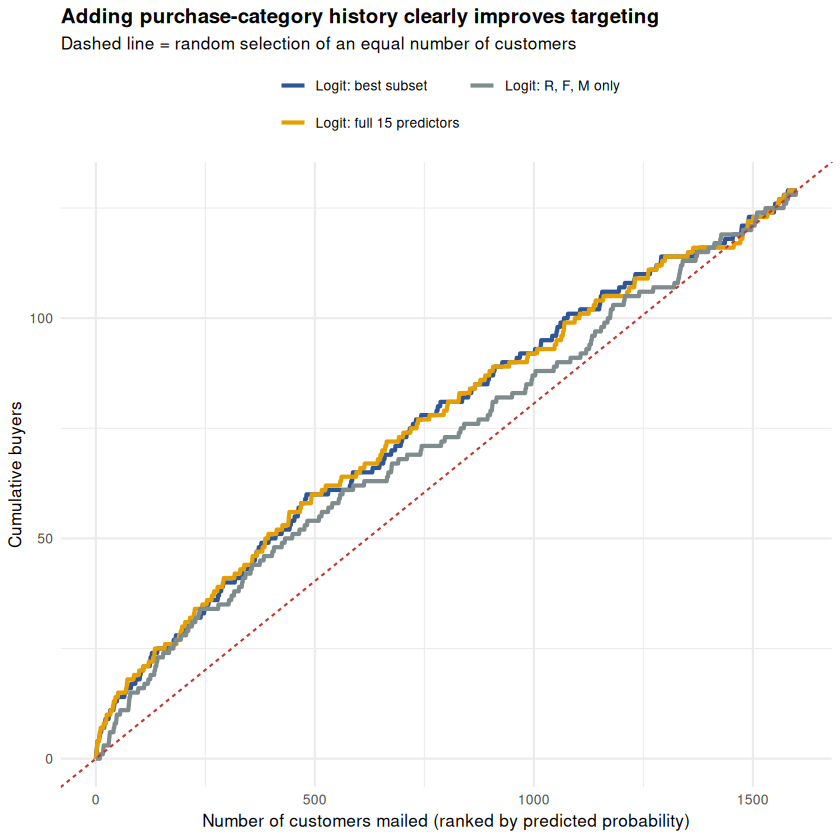

In [46]:
p.full <- predict(logit.full,valid,type = "response")
p.subset <- predict(logit.step,valid,type = "response")
p.rfm <- predict(logit.rfm,valid,type = "response")

g_logit <- bind_rows(
  gains_curve(p.full,valid$Florence,"Logit: full 15 predictors"),
  gains_curve(p.subset,valid$Florence,"Logit: best subset"),
  gains_curve(p.rfm,valid$Florence,"Logit: R, F, M only"))

ggplot(g_logit,aes(Customers,Buyers,colour = Model)) +
geom_line(linewidth = 0.9) +
geom_abline(slope = mean(valid$Florence),intercept = 0,linetype = "dashed",colour = col_base) +
scale_colour_manual(values = c(col_buy,"#E69F00","#7F8C8D")) +
guides(colour = guide_legend(nrow = 2)) +
labs(x = "Number of customers mailed (ranked by predicted probability)",
     y = "Cumulative buyers",colour = NULL,
     title = "Adding purchase-category history clearly improves targeting",
     subtitle = "Dashed line = random selection of an equal number of customers")

In [47]:
lift_tbl <- bind_rows(
  lift_at(p.full,valid$Florence) |> mutate(Model = "Full 15"),
  lift_at(p.subset,valid$Florence) |> mutate(Model = "Best subset"),
  lift_at(p.rfm,valid$Florence) |> mutate(Model = "RFM only")) |>
  select(Model,everything())
kable(lift_tbl,caption = "Buyers captured in the top-N validation customers vs random selection")



Table: Buyers captured in the top-N validation customers vs random selection

|Model       | TopN|Pct | ModelBuyers| RandomBuyers| Lift|
|:-----------|----:|:---|-----------:|------------:|----:|
|Full 15     |  160|10% |          26|         12.9| 2.02|
|Full 15     |  320|20% |          42|         25.8| 1.63|
|Full 15     |  480|30% |          58|         38.7| 1.50|
|Full 15     |  800|50% |          79|         64.5| 1.22|
|Best subset |  160|10% |          25|         12.9| 1.94|
|Best subset |  320|20% |          41|         25.8| 1.59|
|Best subset |  480|30% |          59|         38.7| 1.52|
|Best subset |  800|50% |          81|         64.5| 1.26|
|RFM only    |  160|10% |          24|         12.9| 1.86|
|RFM only    |  320|20% |          38|         25.8| 1.47|
|RFM only    |  480|30% |          53|         38.7| 1.37|
|RFM only    |  800|50% |          73|         64.5| 1.13|

Both models incorporating category and title history (full and subset) perform clearly better than random selection. Mailing the top 10% of customers roughly doubles the number of buyers identified. Among the top 20% of validation customers (320), the full model captures approximately 42 of 129 buyers, compared with 26 expected from random selection, yielding a lift of about 1.63×. The full and subset models perform almost identically, making the simpler subset model equally effective. By comparison, the RFM-only model is weaker, with a lift of 1.47× at the same depth and a lower AUC. This reinforces the earlier finding that reading preferences provife predictive power beyond recency, purchase frequency and spending.

### Targeting using a 30% purchase-probability cut-off

In [48]:
cutoff <- 0.30
target_tbl <- data.frame(
  Model = c("Full 15","Best subset","RFM only"),
  MaxProb = sapply(list(p.full,p.subset,p.rfm),max),
  Targeted = sapply(list(p.full,p.subset,p.rfm), function(p) sum(p >= cutoff)),
  Buyers = sapply(list(p.full,p.subset,p.rfm), function(p) sum(valid$Florence[p >= cutoff]))) |>
  mutate(HitRate = ifelse(Targeted > 0,percent(Buyers/Targeted,0.1), "n/a"))
kable(target_tbl,digits = 3)



|Model       | MaxProb| Targeted| Buyers|HitRate |
|:-----------|-------:|--------:|------:|:-------|
|Full 15     |   0.601|       25|     10|40.0%   |
|Best subset |   0.612|       24|      9|37.5%   |
|RFM only    |   0.215|        0|      0|n/a     |

At a 30% probability cut-off, the full model targets 25 validation customers, of whom 10 are buyers, giving a 40.0% hit rate, nearly five times the 8.1% baseline. The subset model targets 24 customers and identifies 9 buyers. In contrast, the RFM-only model targets no customers because its maximum predicted probability is just 0.215. Although the 30% cut-off produces a highly efficient mailing, it is overly conservative and excludes most potential buyers. In practice, CBC should determine the cut-off based on mailing costs and book margins, guided by the lift chart above.

### Model Comparison

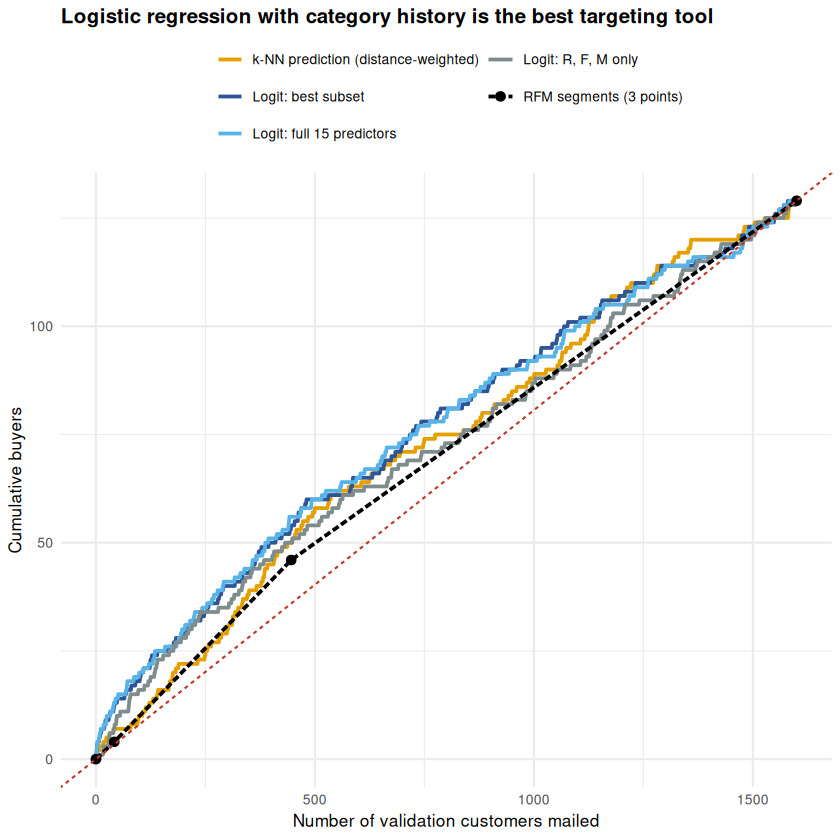

In [49]:
rfm_points <- lift_rfm |> transmute(Model = "RFM segments (3 points)",
                                    Customers = CumCustomers,Buyers = CumBuyers)
all_curves <- bind_rows(g_knnp,g_logit |> filter(Model != "Logit: full 15 predictors"),
                        gains_curve(p.full,valid$Florence,"Logit: full 15 predictors"))

ggplot(all_curves,aes(Customers,Buyers,colour = Model)) +
geom_line(linewidth = 0.8) +
geom_line(data = rfm_points,linewidth = 0.8,linetype = "longdash") +
geom_point(data = rfm_points,size = 2) +
geom_abline(slope = mean(valid$Florence),intercept = 0,linetype = "dashed",colour = col_base) +
scale_colour_manual(values = c("#E69F00",col_buy,"#56B4E9","#7F8C8D","#000000")) +
guides(colour = guide_legend(nrow = 3)) +
labs(x = "Number of validation customers mailed",y = "Cumulative buyers",colour = NULL,
     title = "Logistic regression with category history is the best targeting tool")

In [50]:
summary_tbl <- data.frame(
  Approach = c("RFM above-average cells","k-NN classification","k-NN prediction",
               "Logit full 15","Logit best subset","Logit RFM only"),
  AUC = c(NA,auc(knn_score,valid$Florence),auc(knn_pred,valid$Florence),
          auc(p.full,valid$Florence),auc(p.subset,valid$Florence),auc(p.rfm,valid$Florence)),
  Buyers_in_top_320 = c(NA,sapply(list(knn_score,knn_pred,p.full,p.subset,p.rfm),
                         function(s) sum(valid$Florence[order(s,decreasing = TRUE)][1:320]))))
                                   
summary_tbl$Lift_top_320 <- round(summary_tbl$Buyers_in_top_320/(320*mean(valid$Florence)),2)

kable(summary_tbl,digits = 3,
      caption = paste0("RFM row is not ranked: its above-average cells mail ",rfm_val["Mailed"],
                       " customers, giving a lift of ",round(rfm_val["Lift"],2),"x"))



Table: RFM row is not ranked: its above-average cells mail 446 customers, giving a lift of 1.28x

|Approach                |   AUC| Buyers_in_top_320| Lift_top_320|
|:-----------------------|-----:|-----------------:|------------:|
|RFM above-average cells |    NA|                NA|           NA|
|k-NN classification     | 0.558|                33|         1.28|
|k-NN prediction         | 0.567|                34|         1.32|
|Logit full 15           | 0.599|                42|         1.63|
|Logit best subset       | 0.599|                41|         1.59|
|Logit RFM only          | 0.564|                38|         1.47|

Across the relevant mailing depths (top 10–50% of the list), the two logistic models incorporating reading history consistently outperform the alternatives. Mailing 320 validation customers at random would yield approximately 25.8 buyers. The best logistic model identifies about 42 (lift 1.63×), compared with 34 for k-NN (1.32×). RFM targeting achieves a similar lift (1.28×), but only at one fixed mailing depth because its three-segment structure provides a coarse ranking, with many cells too small for reliable estimates. 

However, AUC values of approximately 0.56–0.60 indicate that even the best model has only modest discriminatory power. Predicting responses to a single title remains difficult; the gains come from improving the odds of reaching buyers rather than identifying them precisely.


### Conclusion and Recommendations
Key findings:<br>
• Untargeted mailing is inefficient. Only 8.4% of members purchased *The Art History of Florence*, meaning that more than nine in ten blanket-mailed letters generate no sale.

• Product affinity outperforms RFM. Previous purchases of art and geography books are the strongest predictors of response. Members who purchased three or more art books respond at approximately 31%. Recency and frequency also contribute, while monetary value has little predictive power. Cookery and children’s-book buyers are less likely to respond.<br>

• Traditional RFM segmentation overfits the training data. Cells with exceptionally high training response rates lose most of their advantage in validation, achieving a lift of only about 1.28×.<br>

• k-NN offers limited targeting improvement. With few buyers and predominantly RFM-based predictors, the best model (k = 8) achieves only about 1.3× lift among the top 20% of customers. Distance weighting provides a finer ranking but delivers similar lift.<br>

• Logistic regression with category history performs best. It approximately doubles the number of buyers reached per letter within the top 10% of the list and achieves a lift of about 1.6× among the top 20%. The more compact subset model performs as well as the full model.

Recommendations for Charles Book Club:
1. Prioritise high-propensity customers. Score the full 500,000-member database using the subset logistic model and mail customers in descending order of predicted purchase probability.

2. Determine the mailing depth based on profitability. Use the lift chart alongside mailing costs and expected profit per sale. Continue mailing while the expected margin per letter (purchase probability × profit per sale) exceeds the mailing cost. The 30% probability cut-off is too restrictive and excludes most potential buyers.

3. Validate before implementation. Confirm the model's performance using a fresh hold-out sample.

4. Develop customer-interest profiles. Build profiles covering interests such as art, travel and cookery for all members. Repeat the modelling and targeting process for each new title, using RFM measures as supporting predictors rather than the primary targeting criteria.
